# Rural Wildfires in Portugal (SGIF 2001-2025)

## Objective

**Research question:** Do rural wildfire characteristics differ across different municipalities and between the periods before and after 2017?

1. Does the proportion of negligent versus intentional wildfires differ between the periods before and after 2017 in mainland Portugal?
2. Does the proportion of wildfires lasting more than 24 hours differ across the municipalities of Paredes, Castelo de Paiva, Évora, and Santarém?
3. Does the time to first intervention differ between the periods before and after 2017 in mainland Portugal?
4. Does the duration of rural wildfires differ across the municipalities of Paredes, Castelo de Paiva, Évora, and Santarém?
5. Is the time to first intervention associated with the burned area of rural wildfires in mainland Portugal?

## Variables per question

| Question | Response variable | Explanatory variable |
|---|---|---|
| 1 | `TipoCausa` (negligent / intentional) | period, from `Ano` |
| 2 | `IncSup24horas` (more than 24 h or not) | `Concelho` |
| 3 | time to first intervention = `DataHora_PrimeiraIntervencao` - `DataHoraAlerta` | period, from `Ano` |
| 4 | `Duracao_Horas` | `Concelho` |
| 5 | `AreaTotal_ha` | time to first intervention |

What each one is:

- `Codigo_SGIF`: id of the fire in the SGIF system
- `Ano`: year of the fire
- `Distrito`, `Concelho`: district and municipality
- `TipoCausa`: type of cause (Negligente, Intencional, Natural, Reacendimento, Desconhecida)
- `DataHoraAlerta`: date and time of the alert
- `DataHora_PrimeiraIntervencao`: date and time the first team started fighting the fire
- `DataHora_Extincao`: date and time the fire was put out
- `Duracao_Horas`: hours from alert to extinction
- `IncSup24horas`: 1 if the fire lasted more than 24 hours, 0 otherwise
- `AreaTotal_ha`: total burned area in hectares

`Distrito` and `DataHora_Extincao` are not in any question, we keep them to check `Concelho` and `Duracao_Horas`.

## Parameters

In [28]:
LAST_YEAR_BEFORE = 2017      # 2017 counts as "before". change to 2016 to move it to "after"
MUNICIPALITIES = ["Paredes", "Castelo de Paiva", "Évora", "Santarém"]

## Import data

In [29]:
import os

os.chdir(r"S:\FEUP\FCED\Stats\Project\GitHub\Statistics_Project-diogo\Statistics_Project-diogo")

In [30]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

data2001_2010 = pd.read_excel("Registos_Incendios_SGIF_2001_2010.xlsx")
data2011_2020 = pd.read_excel("Registos_Incendios_SGIF_2011_2020.xlsx")
data2021_2025 = pd.read_excel("Registos_Incendios_SGIF_2021_2025.xlsx")

# the three files have the same columns, so we stack them
data = pd.concat([data2001_2010, data2011_2020, data2021_2025], ignore_index=True)
data.shape

(497478, 41)

## Keep only the variables we need

In [31]:
keep = ["Codigo_SGIF", "Ano", "Distrito", "Concelho", "TipoCausa",
        "DataHoraAlerta", "DataHora_PrimeiraIntervencao", "DataHora_Extincao",
        "Duracao_Horas", "IncSup24horas", "AreaTotal_ha"]
unused = [c for c in data.columns if c not in keep]

print("before:", data.shape)
print("dropped:", unused)
data = data.drop(columns=unused)
print("after: ", data.shape)
data.head()

before: (497478, 41)
dropped: ['Codigo_ANEPC', 'Mes', 'Dia', 'Hora', 'AreaPov_ha', 'AreaMato_ha', 'AreaAgric_ha', 'ClasseArea', 'DTCCFR', 'Freguesia', 'Local', 'RNAP', 'RNMPF', 'X_Militar', 'Y_Militar', 'Latitude', 'Longitude', 'X_ETRS89', 'Y_ETRS89', 'DSR', 'FWI', 'ISI', 'DC', 'DMC', 'FFMC', 'BUI', 'CodCausa', 'GrupoCausa', 'DescricaoCausa', 'FonteAlerta']
after:  (497478, 11)


,Codigo_SGIF,Ano,AreaTotal_ha,DataHoraAlerta,DataHora_PrimeiraIntervencao,DataHora_Extincao,Duracao_Horas,IncSup24horas,Distrito,Concelho,TipoCausa
0,AT901106,2001,0.0001,2001-01-05 02:00:00,NaT,2001-01-05 02:51:00,0.850000,0,Beja,Cuba,NaN
1,BL201479,2001,0.0100,2001-01-05 14:18:00,NaT,2001-01-05 14:23:00,0.083333,0,Coimbra,Coimbra,NaN
2,TM90152,2001,0.0100,2001-01-05 21:00:00,NaT,2001-01-05 22:35:00,1.583333,0,Bragança,Mirandela,NaN
3,BL101313,2001,0.1000,2001-01-06 13:05:00,NaT,2001-01-06 13:15:00,0.166667,0,Aveiro,Albergaria-a-Velha,NaN
4,BL201156,2001,0.0000,2001-01-07 00:16:00,NaT,2001-01-07 01:20:00,1.066667,0,Coimbra,Coimbra,NaN


## Data check

In [32]:
data.dtypes

Codigo_SGIF                             object
Ano                                      int64
AreaTotal_ha                           float64
DataHoraAlerta                  datetime64[ns]
DataHora_PrimeiraIntervencao    datetime64[ns]
DataHora_Extincao                       object
Duracao_Horas                          float64
IncSup24horas                            int64
Distrito                                object
Concelho                                object
TipoCausa                               object
dtype: object

In [33]:
# missing values per column
data.isna().sum()

Codigo_SGIF                          0
Ano                                  0
AreaTotal_ha                         0
DataHoraAlerta                       0
DataHora_PrimeiraIntervencao    214771
DataHora_Extincao                  513
Duracao_Horas                      513
IncSup24horas                        0
Distrito                             1
Concelho                             1
TipoCausa                       249994
dtype: int64

In [34]:
# missing values per year, only columns that have some
cols_na = data.columns[data.isna().any()]
data[cols_na].isna().groupby(data["Ano"]).sum()

,DataHora_PrimeiraIntervencao,DataHora_Extincao,Duracao_Horas,Distrito,Concelho,TipoCausa
Ano,,,,,,
2001,28915,0,0,0,0,26644
2002,28993,0,0,0,0,26327
2003,28087,0,0,0,0,25724
2004,27829,0,0,0,0,25691
2005,41689,0,0,0,0,38237
2006,24192,0,0,0,0,21169
2007,25131,0,0,0,0,15585
2008,2917,0,0,0,0,9185
2009,4045,1,1,0,0,15084


In [35]:
print("rows:", len(data))
print("unique Codigo_SGIF:", data["Codigo_SGIF"].nunique())
print("years:", data["Ano"].min(), "to", data["Ano"].max())

# Codigo_SGIF comes as text in some files and as number in others
data["Codigo_SGIF"].map(type).value_counts()

rows: 497478
unique Codigo_SGIF: 497478
years: 2001 to 2025


Codigo_SGIF
<class 'str'>    475448
<class 'int'>     22030
Name: count, dtype: int64

In [36]:
data[["Duracao_Horas", "IncSup24horas", "AreaTotal_ha"]].describe()

,Duracao_Horas,IncSup24horas,AreaTotal_ha
count,496965.000000,497478.000000,497478.000000
mean,1.947655,0.007210,6.994419
std,7.995199,0.084607,235.970910
min,0.000000,0.000000,0.000000
25%,0.566667,0.000000,0.010000
50%,1.033333,0.000000,0.050000
75%,1.800000,0.000000,0.500000
max,2474.316667,1.000000,65478.286936


In [37]:
print(data["TipoCausa"].value_counts(dropna=False))
print()
print(data["Distrito"].value_counts())

TipoCausa
NaN              249994
Desconhecida      84395
Negligente        83660
Intencional       48013
Reacendimento     29376
Natural            2040
Name: count, dtype: int64

Distrito
Porto               105679
Braga                57121
Aveiro               40812
Lisboa               40704
Viseu                39210
Vila Real            32471
Viana do Castelo     29424
Santarém             22334
Setúbal              19149
Guarda               17764
Leiria               17492
Bragança             16176
Coimbra              15063
Castelo Branco       12887
Faro                  9385
Beja                  7195
Portalegre            6310
Évora                 6236
Viana Do Castelo      2064
BRAGA                    1
Name: count, dtype: int64


In [38]:
# our municipalities, ignoring upper/lower case
ours = [m.lower() for m in MUNICIPALITIES]
mask = data["Concelho"].str.lower().isin(ours)
data.loc[mask].groupby(["Distrito", "Concelho"]).size()

Distrito  Concelho        
Aveiro    Castelo De Paiva       41
          Castelo de Paiva     1359
Porto     Paredes             12512
Santarém  Santarém             2987
Évora     Évora                1632
dtype: int64

What we see:

- No duplicated fires: one row per `Codigo_SGIF`. But the id comes as text in some files and as a number in others, so it has to be one type.
- All 18 districts are in mainland Portugal, so there is nothing to remove for "mainland". `Distrito` has case problems (`Viana Do Castelo`, `BRAGA`).
- `Castelo de Paiva` also shows up as `Castelo De Paiva` (41 fires). The four municipalities fall in the expected districts.
- `TipoCausa` is missing for 250k fires, mostly before 2014. This matters for question 1.
- `DataHora_PrimeiraIntervencao` is missing in almost all fires from 2001 to 2007, so question 3 and 5 have little data there.
- `Duracao_Horas` and `DataHora_Extincao` are missing in the same 513 rows. Duration goes from 0 to 2474 hours.
- One fire in 2024 has no `Distrito` or `Concelho`.

## Cleaning: municipalities and types

We work at the municipality level (`Concelho`). Paredes and Castelo de Paiva are only municipalities. Évora and Santarém are also district names, but we want the municipality, not the whole district (for example Évora has 6236 fires as a district and 1632 as a municipality).

`Distrito` was only kept to check that, so we drop it now.

In [39]:
# the fire with no municipality can't be used
print("no Concelho:", data["Concelho"].isna().sum())
data = data.dropna(subset=["Concelho"])

data = data.drop(columns=["Distrito"])
data.shape

no Concelho: 1


(497477, 10)

In [40]:
# same municipality written with different case: "Castelo de Paiva" / "Castelo De Paiva", "ODIVELAS" / "Odivelas"
print("names before:", data["Concelho"].nunique())
data["Concelho"] = data["Concelho"].str.title()
print("names after: ", data["Concelho"].nunique())

MUNICIPALITIES = [m.title() for m in MUNICIPALITIES]
data.loc[data["Concelho"].isin(MUNICIPALITIES), "Concelho"].value_counts()

names before: 379
names after:  278


Concelho
Paredes             12512
Santarém             2987
Évora                1632
Castelo De Paiva     1400
Name: count, dtype: int64

From 379 names to 278, which is the number of municipalities in mainland Portugal. Castelo de Paiva goes from 1359 to 1400 fires.

In [41]:
# the id is an id, not a number
data["Codigo_SGIF"] = data["Codigo_SGIF"].astype("string")

# text with few values -> category
data["Concelho"] = data["Concelho"].astype("category")
data["TipoCausa"] = data["TipoCausa"].astype("category")

data.dtypes

Codigo_SGIF                     string[python]
Ano                                      int64
AreaTotal_ha                           float64
DataHoraAlerta                  datetime64[ns]
DataHora_PrimeiraIntervencao    datetime64[ns]
DataHora_Extincao                       object
Duracao_Horas                          float64
IncSup24horas                            int64
Concelho                              category
TipoCausa                             category
dtype: object

## Period

In [42]:
# before = up to LAST_YEAR_BEFORE, after = the rest
data["period"] = "after"
data.loc[data["Ano"] <= LAST_YEAR_BEFORE, "period"] = "before"
data["period"] = data["period"].astype("category")

data.groupby("period")["Ano"].agg(["min", "max", "count"])

C:\Users\Diogo Ribeiro\AppData\Local\Temp\ipykernel_27320\1963441539.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  data.groupby("period")["Ano"].agg(["min", "max", "count"])


,min,max,count
period,,,
after,2018,2025,73330
before,2001,2017,424147


## Question 1: cause

In [43]:
# astype(str) so the missing causes show up as "nan"
pd.crosstab(data["TipoCausa"].astype(str), data["period"], margins=True)

period,after,before,All
TipoCausa,,,
Desconhecida,23829,60566,84395
Intencional,13872,34141,48013
Natural,836,1204,2040
Negligente,26201,57459,83660
Reacendimento,3820,25556,29376
nan,4772,245221,249993
All,73330,424147,497477


In [44]:
# only fires with a known negligent or intentional cause
q1 = data[data["TipoCausa"].isin(["Negligente", "Intencional"])]

tab = pd.crosstab(q1["period"], q1["TipoCausa"].astype(str), margins=True)
tab["share negligent"] = (tab["Negligente"] / tab["All"]).round(3)
tab

TipoCausa,Intencional,Negligente,All,share negligent
period,,,,
after,13872,26201,40073,0.654
before,34141,57459,91600,0.627
All,48013,83660,131673,0.635


In [45]:
# how many causes were classified each year
by_year = pd.crosstab(q1["Ano"], q1["TipoCausa"].astype(str))
by_year["share negligent"] = (by_year["Negligente"] / by_year.sum(axis=1)).round(2)
by_year

TipoCausa,Intencional,Negligente,share negligent
Ano,,,
2001,475,391,0.45
2002,394,414,0.51
2003,436,522,0.54
2004,364,421,0.54
2005,619,456,0.42
2006,381,502,0.57
2007,1424,3203,0.69
2008,1570,3490,0.69
2009,3540,5190,0.59


For question 1 we keep only the fires with cause `Negligente` or `Intencional`. Missing, unknown, rekindling and natural causes are left out, we don't impute a cause.

## Questions 2 and 4: duration

In [46]:
print("missing duration:", data["Duracao_Horas"].isna().sum())
print("duration = 0:    ", (data["Duracao_Horas"] == 0).sum())

# a fire can't be put out the same minute it is reported, and without duration we can't use it
before = len(data)
data = data[data["Duracao_Horas"] > 0]
print("rows removed:", before - len(data), "of", before)

missing duration: 513
duration = 0:     636
rows removed: 1149 of 497477


In [47]:
# IncSup24horas should be 1 when the fire lasted 24 hours or more
print("mismatches with > 24: ", ((data["Duracao_Horas"] > 24).astype(int) != data["IncSup24horas"]).sum())
print("mismatches with >= 24:", ((data["Duracao_Horas"] >= 24).astype(int) != data["IncSup24horas"]).sum())

mismatches with > 24:  29
mismatches with >= 24: 0


The 29 mismatches are fires of exactly 24 hours. SGIF counts them as "more than 24 hours", so `IncSup24horas` is fine as it is.

In [48]:
q24 = data[data["Concelho"].isin(MUNICIPALITIES)].copy()
q24["Concelho"] = q24["Concelho"].cat.remove_unused_categories()

pd.crosstab(q24["Concelho"], q24["IncSup24horas"], margins=True)

IncSup24horas,0,1,All
Concelho,,,
Castelo De Paiva,1384,8,1392
Paredes,12456,36,12492
Santarém,2959,26,2985
Évora,1622,9,1631
All,18421,79,18500


In [49]:
q24.groupby("Concelho")["Duracao_Horas"].describe()

C:\Users\Diogo Ribeiro\AppData\Local\Temp\ipykernel_27320\1401063168.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  q24.groupby("Concelho")["Duracao_Horas"].describe()


,count,mean,std,min,25%,50%,75%,max
Concelho,,,,,,,,
Castelo De Paiva,1392.0,1.790577,4.209986,0.050000,0.566667,1.083333,1.666667,83.250000
Paredes,12492.0,1.278609,2.831771,0.016667,0.500000,0.816667,1.250000,143.600000
Santarém,2985.0,1.552446,4.063688,0.016667,0.383333,0.816667,1.450000,82.666667
Évora,1631.0,1.280421,2.416428,0.066667,0.416667,0.700000,1.250000,29.050000


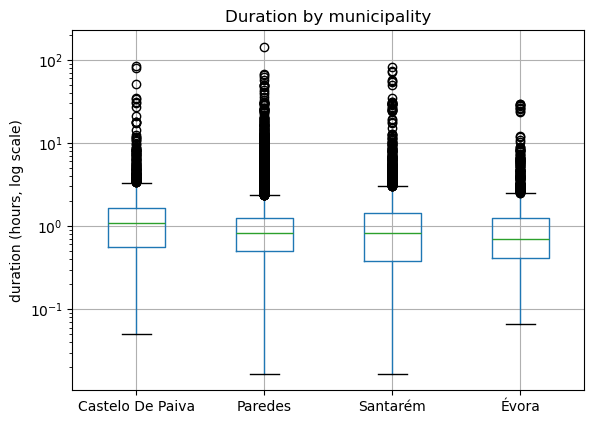

In [50]:
fig, ax = plt.subplots()
q24.boxplot(column="Duracao_Horas", by="Concelho", ax=ax)
ax.set_yscale("log")
ax.set_xlabel("")
ax.set_ylabel("duration (hours, log scale)")
ax.set_title("Duration by municipality")
plt.suptitle("")
plt.show()

We keep the long fires (up to 144 hours in Paredes). They are outliers, but real ones: big fires that tell us about specific events. Duration is very skewed (median around 1 hour), so the log scale is needed to see anything.

## Questions 3 and 5: time to first intervention

There is no column with this time, we compute it from the alert and the first intervention.

In [51]:
data["time_first_intervention_min"] = (data["DataHora_PrimeiraIntervencao"] - data["DataHoraAlerta"]).dt.total_seconds() / 60
data["time_first_intervention_min"].describe()

count    2.821910e+05
mean     3.846804e+01
std      1.287085e+04
min      0.000000e+00
25%      7.000000e+00
50%      1.100000e+01
75%      1.600000e+01
max      6.837131e+06
Name: time_first_intervention_min, dtype: float64

In [52]:
# the first intervention date only exists from 2008
data.groupby("Ano")["time_first_intervention_min"].count()

Ano
2001        0
2002        0
2003        0
2004        0
2005        0
2006       51
2007        1
2008    16040
2009    25737
2010    23765
2011    29526
2012    25211
2013    23051
2014     9355
2015    19632
2016    16090
2017    20983
2018    12268
2019    10696
2020     9565
2021     8160
2022    10350
2023     7511
2024     6111
2025     8088
Name: time_first_intervention_min, dtype: int64

Before 2008 there is almost no intervention date (51 fires in 2006, 1 in 2007), so for question 3 the "before" period is really 2008 to 2017.

In [54]:
# intervention after extinction is not possible, and time = 0 looks like the alert time copied
data["DataHora_Extincao"] = pd.to_datetime(
    data["DataHora_Extincao"], errors="coerce"
)

after_ext = data["DataHora_PrimeiraIntervencao"] > data["DataHora_Extincao"]
zero = data["time_first_intervention_min"] == 0
print("intervention after extinction:", after_ext.sum())
print("time = 0:                     ", zero.sum())

# only the time is wrong, the fire is still fine for the other questions
data.loc[after_ext | zero, "time_first_intervention_min"] = None
data["time_first_intervention_min"].describe()

intervention after extinction: 3968
time = 0:                      2387


count    275836.000000
mean         13.943822
std          25.574472
min           1.000000
25%           7.000000
50%          11.000000
75%          16.000000
max        1488.000000
Name: time_first_intervention_min, dtype: float64

In [55]:
data.groupby("period")["time_first_intervention_min"].agg(["count", "median", "mean"])

C:\Users\Diogo Ribeiro\AppData\Local\Temp\ipykernel_27320\689315257.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  data.groupby("period")["time_first_intervention_min"].agg(["count", "median", "mean"])


,count,median,mean
period,,,
after,71456,13.0,16.104764
before,204380,10.0,13.188306


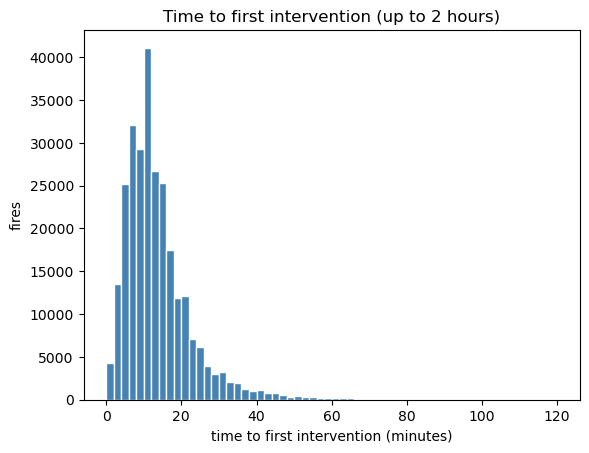

In [56]:
fig, ax = plt.subplots()
ax.hist(data["time_first_intervention_min"].dropna(), bins=range(0, 121, 2), color="steelblue", edgecolor="white")
ax.set_xlabel("time to first intervention (minutes)")
ax.set_ylabel("fires")
ax.set_title("Time to first intervention (up to 2 hours)")
plt.show()

In [57]:
# Q3: intervention time before versus after 2017
q3 = data.loc[
    data["Ano"].between(2008, 2025)
].dropna(subset=["time_first_intervention_min"]).copy()

# Q5: intervention time versus burned area
q5 = q3.dropna(subset=["AreaTotal_ha"]).copy()

In [58]:
q5[["time_first_intervention_min", "AreaTotal_ha"]].describe()

,time_first_intervention_min,AreaTotal_ha
count,275786.000000,275786.000000
mean,13.943859,7.577518
std,25.576502,286.913031
min,1.000000,0.000000
25%,7.000000,0.010000
50%,11.000000,0.050000
75%,16.000000,0.500000
max,1488.000000,65478.286936


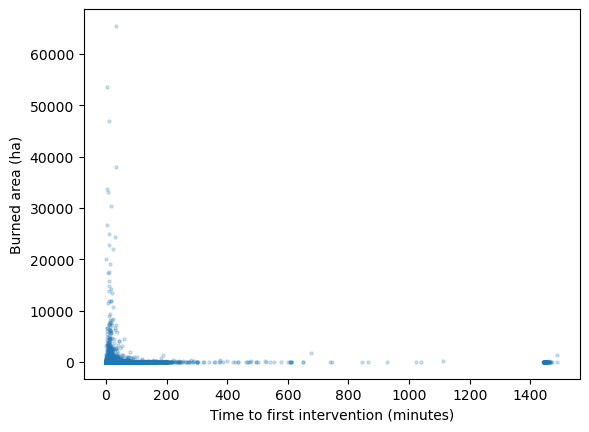

In [59]:
plt.scatter(
    q5["time_first_intervention_min"],
    q5["AreaTotal_ha"],
    alpha=0.2,
    s=5
)

plt.xlabel("Time to first intervention (minutes)")
plt.ylabel("Burned area (ha)")
plt.show()

## Questions 3 and 5: analysis datasets

We restrict these analyses to 2008–2025 because first-intervention
timestamps are almost entirely missing before 2008.
We use the intervention times retained after the cleaning above.

In [61]:
# Q3: intervention time by period
q3 = data.loc[
    data["Ano"].between(2008, 2025)
].dropna(subset=["time_first_intervention_min"]).copy()

# Q5: intervention time and burned area
q5 = q3.dropna(subset=["AreaTotal_ha"]).copy()

print("Q3 observations:", len(q3))
print("Q5 observations:", len(q5))

Q3 observations: 275786
Q5 observations: 275786


In [62]:
q5[["time_first_intervention_min", "AreaTotal_ha"]].describe()

,time_first_intervention_min,AreaTotal_ha
count,275786.000000,275786.000000
mean,13.943859,7.577518
std,25.576502,286.913031
min,1.000000,0.000000
25%,7.000000,0.010000
50%,11.000000,0.050000
75%,16.000000,0.500000
max,1488.000000,65478.286936


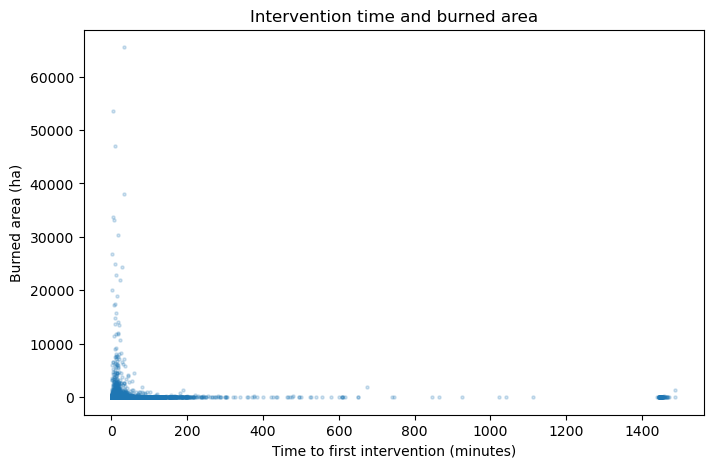

In [63]:
plt.figure(figsize=(8, 5))

plt.scatter(
    q5["time_first_intervention_min"],
    q5["AreaTotal_ha"],
    alpha=0.2,
    s=5
)

plt.xlabel("Time to first intervention (minutes)")
plt.ylabel("Burned area (ha)")
plt.title("Intervention time and burned area")
plt.show()

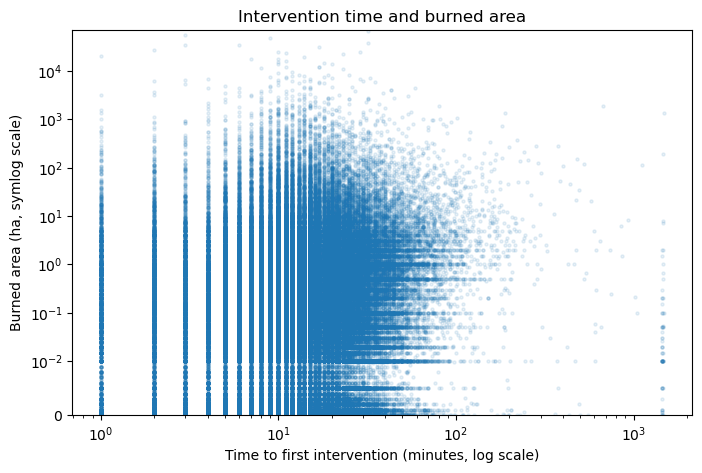

In [65]:
plt.figure(figsize=(8, 5))

plt.scatter(
    q5["time_first_intervention_min"],
    q5["AreaTotal_ha"],
    alpha=0.1,
    s=5
)

plt.xscale("log")
plt.yscale("symlog", linthresh=0.01)

plt.xlabel("Time to first intervention (minutes, log scale)")
plt.ylabel("Burned area (ha, symlog scale)")
plt.title("Intervention time and burned area")
plt.ylim(bottom=0)
plt.show()

## Question 1: Comparison of wildfire causes between periods

Does the proportion of negligent versus intentional wildfires differ
between 2001–2017 and 2018–2025 in mainland Portugal?

This analysis includes only fires classified as negligent or intentional.

### Hypotheses

Let p_before and p_after represent the population proportions of negligent
fires among fires classified as negligent or intentional in each period.

- H₀: p_before = p_after
- H₁: p_before ≠ p_after

We use a two-sided two-proportion z-test at a significance level of α = 0.05.

### Conditions and assumptions

**Independence**

Each record represents a separate fire, and the two periods contain
different fires, so the observations are not paired. Independence within
and between periods is assumed. Shared temporal and geographical factors
may limit this assumption.

The data are administrative records rather than random samples.
Generalisation is also limited by missing and unknown causes,
particularly in the earlier period.

**Success–failure condition**

Under H₀, both periods share the same population proportion.
We estimate it using the pooled sample proportion.

Each period must have at least 10 expected negligent fires and
10 expected intentional fires under H₀. We check this below.

In [97]:
# Count negligent and intentional fires in each period.

cause_table = pd.crosstab(q1["period"], q1["TipoCausa"])
cause_table

TipoCausa,Intencional,Negligente
period,,
after,13872,26201
before,34141,57459


### Checking the success–failure condition

The pooled proportion of negligent fires is:

p_pooled = (57,459 + 26,201) / (91,600 + 40,073)
         = 83,660 / 131,673
         ≈ 0.63536.

Expected counts equal each period's total multiplied by the pooled
proportion for the corresponding cause.

| Period | Expected negligent | Expected intentional |
|---|---|---|
| Before | 91,600 × 0.63536 ≈ 58,199 | 91,600 × 0.36464 ≈ 33,401 |
| After | 40,073 × 0.63536 ≈ 25,461 | 40,073 × 0.36464 ≈ 14,612 |

All four expected counts exceed 10, satisfying the success-failure condition.

In [80]:
from statsmodels.stats.proportion import proportions_ztest

# Count fires by period and cause.
table = pd.crosstab(q1["period"], q1["TipoCausa"])

# Keep the same order for both: before, after.
counts = table.loc[["before", "after"], "Negligente"]
totals = table.loc[
    ["before", "after"], ["Negligente", "Intencional"]
].sum(axis=1)

# Calculate and display the observed percentages.
proportions = counts / totals
print("Negligent fires (%):")
print((proportions * 100).round(2))

# Calculate the change in percentage points.
difference_pp = (proportions["after"] - proportions["before"]) * 100
print(f"\nDifference (after − before): {difference_pp:.2f} percentage points")

# Compare the two population proportions.
z_stat, p_value = proportions_ztest(
    counts, totals, alternative="two-sided"
)

print("\nz-statistic:", z_stat)
print("p-value:", p_value)

Negligent fires (%):
period
before    62.73
after     65.38
dtype: float64

Difference (after − before): 2.66 percentage points

z-statistic: -9.209791568067667
p-value: 3.26758802987174e-20


### Results and conclusion

The proportion of negligent fires was 62.73% in 2001–2017 and
65.38% in 2018–2025, an increase of approximately 2.66 percentage points.

The two-sided two-proportion z-test gave z = −9.21 and
p = 3.27 × 10⁻²⁰. At the 5% significance level, we reject H₀.

There is statistically significant evidence that the proportion of
negligent fires among fires classified as negligent or intentional
differs between the periods, with a higher proportion after 2017.

Although statistically significant, the observed difference is modest.
The comparison excludes other and missing causes; cause information
was substantially less complete in the earlier period, which limits
generalisation to all wildfires.

### Exam reference: reusable two-proportion z-test

Adapt the dataset, column names, group labels, outcome labels,
alternative hypothesis and significance level (`alpha`) before running.
Check the conditions for the new data.

#### Hypotheses

Let p₁ and p₂ represent the population proportions of the outcome
defined as "success" in groups 1 and 2.

- H₀: p₁ = p₂
- H₁: p₁ ≠ p₂ — use `alternative="two-sided"`.

For a one-sided test, adapt H₁ and the code:

- H₁: p₁ > p₂ — use `alternative="larger"`.
- H₁: p₁ < p₂ — use `alternative="smaller"`.

#### Conditions checklist

**Binary outcome**

The same success/failure outcome is measured in two groups.

**Independence**

Observations are independent within and between groups.
The data are not paired.

**Data collection**

Explain random sampling or random assignment, if applicable.
Otherwise, acknowledge limitations to generalisation.

For sampling without replacement, check that each sample is less
than 10% of its population.

**Success–failure condition**

Let x₁ and x₂ be the numbers of successes, and n₁ and n₂ the total
observations in each group.

Under H₀: p₁ = p₂, calculate the pooled proportion:

p_pool = (x₁ + x₂) / (n₁ + n₂)

Check that all four expected counts are at least 10:

| Group | Expected successes | Expected failures |
|---|---|---|
| 1 | n₁ × p_pool ≥ 10 | n₁ × (1 − p_pool) ≥ 10 |
| 2 | n₂ × p_pool ≥ 10 | n₂ × (1 − p_pool) ≥ 10 |

Normality of the original data, equal group sizes and equal population
variances are not required.

In [ ]:
# REUSABLE TEMPLATE — TWO-PROPORTION Z-TEST

from statsmodels.stats.proportion import proportions_ztest

# CHANGE THESE FOR A NEW DATASET
df = q1
group_column = "period"
outcome_column = "TipoCausa"

group1 = "before"
group2 = "after"

success = "Negligente"
failure = "Intencional"

alpha = 0.05  # Change to the significance level given in the question.

# Choose ONE setting according to the question:
# "two-sided" → H1: p1 ≠ p2
# "larger"    → H1: p1 > p2
# "smaller"   → H1: p1 < p2
# Here, p1 = proportion in group1; p2 = proportion in group2.
alternative = "two-sided"

# KEEP THE CODE BELOW THE SAME
# Count the two outcomes in each group.
table = pd.crosstab(df[group_column], df[outcome_column])

table = table.reindex(
    index=[group1, group2],
    columns=[success, failure],
    fill_value=0
)

counts = table[success]
totals = table.sum(axis=1)

# Observed percentages of the outcome defined as "success".
proportions = counts / totals
print("Success (%):")
print((proportions * 100).round(2))

# Descriptive difference: group2 minus group1.
difference_pp = (proportions[group2] - proportions[group1]) * 100
print(f"\nDifference ({group2} − {group1}): {difference_pp:.2f} percentage points")

# Test compares group1 minus group2.
z_stat, p_value = proportions_ztest(
    counts, totals, alternative=alternative
)

print("\nz-statistic:", z_stat)
print("p-value:", p_value)

if p_value < alpha:
    print("Reject H0.")
else:
    print("Do not reject H0.")

## Question 2: Proportion of fires lasting 24 hours or longer by municipality

Does the proportion of fires lasting 24 hours or longer differ between
Paredes, Castelo de Paiva, Évora and Santarém?

### Hypotheses

- H₀: The population proportion is equal across all four municipalities.
- H₁: At least one municipality has a different population proportion.

We use a chi-square test of homogeneity at a significance level of α = 0.05.

### Conditions and assumptions

**Independence**

Each record represents a separate fire assigned to one municipality
and one duration category. The municipality groups are not paired.

Independence within and between municipalities is assumed.
Shared temporal and geographical factors may limit this assumption.

The data are administrative records rather than random samples.
Results describe fires retained after the duration cleaning,
which limits generalisation.

**Expected frequencies**

For the chi-square approximation, we check that all expected
frequencies under H₀ are at least 5.

Expected frequency = (row total × column total) / overall total.

These frequencies are calculated below.

In [86]:
# Count fires by municipality and duration category.
# 0 = less than 24 hours; 1 = 24 hours or longer.
duration_table = pd.crosstab(
    q24["Concelho"], q24["IncSup24horas"]
)

# Build a summary table with counts, totals and percentages.
summary_q2 = duration_table.rename(
    columns={0: "Less than 24 h", 1: "24 h or longer"}
).copy()

summary_q2["Total"] = duration_table.sum(axis=1)

summary_q2["24 h or longer (%)"] = (
    100 * duration_table[1] / summary_q2["Total"]
).round(2)

summary_q2

IncSup24horas,Less than 24 h,24 h or longer,Total,24 h or longer (%)
Concelho,,,,
Castelo De Paiva,1384,8,1392,0.57
Paredes,12456,36,12492,0.29
Santarém,2959,26,2985,0.87
Évora,1622,9,1631,0.55


In [87]:
from scipy.stats import chi2_contingency

# Test whether the proportion lasting ≥24 hours is equal
# across the four municipalities. Use observed counts only.
chi2_stat, p_value, dof, expected = chi2_contingency(duration_table)

# Expected counts under H0, used to check the large-count condition.
expected_table = pd.DataFrame(
    expected,
    index=duration_table.index,
    columns=["Less than 24 h", "24 h or longer"]
)

display(expected_table.round(2))
print(f"Smallest expected frequency: {expected.min():.2f}")

print(f"\nChi-square statistic: {chi2_stat:.3f}")
print(f"Degrees of freedom: {dof}")
print(f"p-value: {p_value:.3e}")

,Less than 24 h,24 h or longer
Concelho,,
Castelo De Paiva,1386.06,5.94
Paredes,12438.66,53.34
Santarém,2972.25,12.75
Évora,1624.04,6.96


Smallest expected frequency: 5.94

Chi-square statistic: 20.814
Degrees of freedom: 3
p-value: 1.151e-04


### Results and conclusion

The percentage of fires lasting 24 hours or longer was:

- Castelo de Paiva: 0.57%
- Paredes: 0.29%
- Santarém: 0.87%
- Évora: 0.55%

All expected frequencies exceeded 5 (minimum = 5.94), satisfying
the expected-count condition for the chi-square test.
Independence of observations is assumed.

The chi-square test gave χ²(3) = 20.81, p = 0.000115.
At the 5% significance level, we reject H₀.

There is statistically significant evidence that the proportion of
fires lasting 24 hours or longer differs between at least two of
the four municipalities.

Santarém had the highest observed proportion and Paredes the lowest.
However, this overall test does not establish which specific pairs
of municipalities differ significantly.

Fires lasting 24 hours or longer were uncommon in all municipalities,
representing less than 1% of the analysed fires in each municipality.

### Exam reference: reusable chi-square test for a two-way table

Adapt the dataset, the two categorical column names and the
significance level (`alpha`) before running.

#### Hypotheses

For a test of independence:

- H₀: The two categorical variables are independent.
- H₁: The two categorical variables are associated.

For a test of homogeneity:

- H₀: The population outcome distribution is the same across groups.
- H₁: At least one group has a different population outcome distribution.

For a binary outcome, comparing distributions means comparing
the proportion of that outcome across groups.

#### Conditions checklist

**Categorical variables and counts**

Both variables are categorical. The table contains numbers of
observations, not percentages or measurements.

Each observation contributes to exactly one cell.

**Independence of observations**

Observations are independent within and between groups.
The data are not paired or repeated measurements of the same subjects.

This assumption concerns independence between observations;
H₀ concerns independence between the two variables.

**Data collection**

Explain random sampling or random assignment, if applicable.
Otherwise, acknowledge limitations to generalisation.

For sampling without replacement, check that each sample is less
than 10% of its population.

**Expected frequencies**

Calculate the expected count in each cell under H₀:

Expected count = (row total × column total) / overall total

Following the introductory rule used here, all expected counts
should be at least 5. Check expected counts, not observed counts.

#### Interpretation

Compare the p-value with the chosen significance level.

A significant result indicates an association or a difference
in distributions. It does not identify which specific groups
or categories differ.

Normality of the original data and equal group sizes are not required.

In [ ]:
import pandas as pd
from scipy.stats import chi2_contingency

# REUSABLE TEMPLATE — CHI-SQUARE TEST

# CHANGE THESE FOR A NEW DATASET
df = q24
group_column = "Concelho"
outcome_column = "IncSup24horas"

alpha = 0.05  # Significance level given in the question.

# KEEP THE CODE BELOW THE SAME
# Rows = groups; columns = outcome categories.
# Rows missing either variable are excluded.
table = pd.crosstab(df[group_column], df[outcome_column])

print("Observed counts:")
display(table)

# Percentages within each group (each row sums to 100%).
percentages = table.div(table.sum(axis=1), axis=0) * 100

print("Percentages within each group:")
display(percentages.round(2))

# Perform the chi-square test without continuity correction.
chi2_stat, p_value, dof, expected = chi2_contingency(
    table, correction=False
)

# Expected frequencies under H0.
expected_table = pd.DataFrame(
    expected,
    index=table.index,
    columns=table.columns
)

print("Expected frequencies under H0:")
display(expected_table.round(2))

print(f"Smallest expected frequency: {expected.min():.2f}")
print("All expected frequencies ≥ 5:", (expected >= 5).all())

print(f"\nChi-square statistic: {chi2_stat:.3f}")
print("Degrees of freedom:", dof)
print(f"p-value: {p_value:.3e}")
print("Significance level:", alpha)

# Check the expected-frequency condition before stating a decision.
# Independence and data collection must be assessed separately.
if not (expected >= 5).all():
    print("\nSome expected counts are below 5.")
    print("Review the test's suitability before interpreting the p-value.")
elif p_value < alpha:
    print("\nReject H0: evidence that the outcome distribution differs across groups.")
else:
    print("\nDo not reject H0: insufficient evidence of different outcome distributions.")

## Question 3: Mean time to first intervention by period

Does the population mean time to first intervention differ between
2008–2017 and 2018–2025 in mainland Portugal?

The analysis starts in 2008 because intervention timestamps are almost
entirely missing before that year. Times are measured in minutes.

### Hypotheses

- H₀: μ_before = μ_after
- H₁: μ_before ≠ μ_after

We use a two-sided Welch's independent-samples t-test at α = 0.05.
This test does not assume equal population variances.

### Conditions and assumptions

**Independence**

Each record represents a separate fire, and the two periods contain
different fires, so the observations are not paired.

Independence within and between periods is assumed. Shared temporal
and geographical factors may limit this assumption.

**Sample sizes and skewness**

Intervention times are strongly right-skewed. However, both groups
are very large, supporting an approximately normal sampling
distribution of the difference in means through the Central Limit
Theorem.

Extreme values can still influence the means and the test results.

**Population variances**

Equal population variances are not required because we use
Welch's independent-samples t-test.

**Data coverage**

The analysis includes fires from 2008–2025 retained after cleaning
with available intervention timestamps. The data are administrative
records rather than random samples, and missing or excluded
observations may limit generalisation.

In [72]:
# q3 contains the intervention times retained after cleaning,
# restricted to 2008–2025.
summary_q3 = q3.groupby("period", observed=True)[
    "time_first_intervention_min"
].agg(["count", "mean", "std", "median", "min", "max"])

# Display the earlier period first.
summary_q3.loc[["before", "after"]]

,count,mean,std,median,min,max
period,,,,,,
before,204330,13.188171,27.657496,10.0,1.0,1472.0
after,71456,16.104764,18.195727,13.0,1.0,1488.0


In [92]:
from scipy.stats import ttest_ind

# Select intervention times for each period.
before_times = q3.loc[
    q3["period"] == "before", "time_first_intervention_min"
]

after_times = q3.loc[
    q3["period"] == "after", "time_first_intervention_min"
]

# Observed increase in mean intervention time.
difference = after_times.mean() - before_times.mean()
print(f"Mean difference (after − before): {difference:.2f} minutes")

# Two-sided Welch's t-test: equal population variances are not assumed.
t_stat, p_value = ttest_ind(
    before_times,
    after_times,
    equal_var=False,
    alternative="two-sided"
)

print(f"\nt-statistic: {t_stat:.3f}")
print(f"p-value: {p_value:.3e}")

Mean difference (after − before): 2.92 minutes

t-statistic: -31.866
p-value: 3.038e-222


### Results and conclusion

Mean time to first intervention was 13.19 minutes in 2008–2017
and 16.10 minutes in 2018–2025, an increase of approximately
2.92 minutes. The corresponding medians were 10 and 13 minutes.

The two-sided Welch's t-test gave t = −31.87 and
p = 3.04 × 10⁻²²². At the 5% significance level, we reject H₀.

There is statistically significant evidence that the population mean
time to first intervention differs between periods, with a higher
observed mean after 2017.

The analysis assumes independent observations. Although the groups
are large, intervention times are strongly right-skewed and extreme
values can influence the means.

These results describe fires retained after cleaning and with available
intervention timestamps. They do not establish that changes introduced
after 2017 caused the observed difference.

### Exam reference: reusable independent-samples t-test

Adapt the dataset, column names, group labels, alternative hypothesis,
variance assumption and significance level (`alpha`).

#### Hypotheses

Let μ₁ and μ₂ represent the population means in groups 1 and 2.

- H₀: μ₁ = μ₂
- H₁: μ₁ ≠ μ₂ — use `alternative="two-sided"`.

For a one-sided test:

- H₁: μ₁ > μ₂ — use `alternative="greater"`.
- H₁: μ₁ < μ₂ — use `alternative="less"`.

#### Conditions checklist

**Numerical outcome and two groups**

The response variable is numerical, and the two groups are independent.
For paired observations, use a paired t-test instead.

**Independence**

Observations are independent within and between groups.

**Data collection**

Explain random sampling or random assignment, if applicable.
Otherwise, acknowledge limitations to generalisation.

For sampling without replacement, check that each sample is less
than 10% of its population.

**Distributions and sample sizes**

For small samples, within-group distributions should be approximately
normal, without strong skewness or extreme outliers.

Larger samples allow greater departures from normality. Strong skewness
and influential extreme values still require attention; a large sample
does not automatically resolve every concern.

**Population variances**

- Welch's test (`equal_var=False`) does not assume equal population variances.
- The pooled t-test (`equal_var=True`) assumes equal population variances.

Equal group sizes are not required.

#### Interpretation

Compare the p-value with `alpha`, provided the conditions are adequately met.
Report the group means and their difference alongside the test result.

In [ ]:
import pandas as pd
from scipy.stats import ttest_ind

# REUSABLE TEMPLATE — INDEPENDENT-SAMPLES T-TEST

# CHANGE THESE FOR A NEW DATASET
df = q3
group_column = "period"
value_column = "time_first_intervention_min"

group1 = "before"
group2 = "after"

alpha = 0.05

# Choose ONE setting:
# "two-sided" → H1: μ1 ≠ μ2
# "greater"   → H1: μ1 > μ2
# "less"      → H1: μ1 < μ2
# μ1 refers to group1; μ2 refers to group2.
alternative = "two-sided"

# False = Welch; True = pooled t-test (assumes equal variances).
equal_var = False

# KEEP THE CODE BELOW THE SAME
# Select the two groups and exclude missing numerical values.
values1 = df.loc[df[group_column] == group1, value_column].dropna()
values2 = df.loc[df[group_column] == group2, value_column].dropna()

# Descriptive statistics presented as a table.
summary = pd.DataFrame({
    group1: values1.describe(),
    group2: values2.describe()
}).T

display(summary)

# Descriptive difference: group2 minus group1.
difference = values2.mean() - values1.mean()
print(f"Mean difference ({group2} − {group1}): {difference:.2f}")

# Test compares group1 minus group2.
t_stat, p_value = ttest_ind(
    values1,
    values2,
    equal_var=equal_var,
    alternative=alternative
)

print(f"\nt-statistic: {t_stat:.3f}")
print(f"p-value: {p_value:.3e}")
print("Significance level:", alpha)

# Interpret only after assessing the conditions separately.
if p_value < alpha:
    print("Reject H0: evidence supporting the chosen alternative hypothesis.")
else:
    print("Do not reject H0: insufficient evidence supporting the alternative.")

## Question 4: Mean wildfire duration by municipality

Does the population mean wildfire duration differ between Paredes,
Castelo de Paiva, Évora and Santarém?

Duration is measured in hours.

### Hypotheses

- H₀: The population mean duration is equal across all four municipalities.
- H₁: At least one population mean differs.

The significance level is α = 0.05.

### Conditions and assumptions

**Independence**

Each record represents a separate fire assigned to one municipality.
The groups are not paired. Independence within and between municipalities
is assumed; shared temporal and geographical factors may limit this assumption.

**Group sizes and skewness**

Wildfire durations are strongly right-skewed. However, all four groups
are large, supporting approximately normal sampling distributions
of the group means. Extreme durations can still influence the results.

**Population variances**

We use Welch's one-way ANOVA because the group standard deviations
and sample sizes differ. Equal population variances are not required.

**Data coverage**

The analysis uses administrative records rather than random samples.
Results apply to fires retained after the duration cleaning;
missing and excluded observations may limit generalisation.

In [81]:
# q24 contains the fires retained for the four municipalities
# after your colleague's duration cleaning.
summary_q4 = q24.groupby("Concelho", observed=True)[
    "Duracao_Horas"
].agg(["count", "mean", "std", "median", "min", "max"])

summary_q4

,count,mean,std,median,min,max
Concelho,,,,,,
Castelo De Paiva,1392,1.790577,4.209986,1.083333,0.050000,83.250000
Paredes,12492,1.278609,2.831771,0.816667,0.016667,143.600000
Santarém,2985,1.552446,4.063688,0.816667,0.016667,82.666667
Évora,1631,1.280421,2.416428,0.700000,0.066667,29.050000



We use Welch's one-way ANOVA because it does not assume equal
population variances across municipalities.

In [93]:
from statsmodels.stats.oneway import anova_oneway

# Compare population mean durations without assuming equal variances.
result_q4 = anova_oneway(
    data=q24["Duracao_Horas"],
    groups=q24["Concelho"],
    use_var="unequal"
)

print(f"F-statistic: {result_q4.statistic:.3f}")
print(f"Numerator degrees of freedom: {result_q4.df_num:.2f}")
print(f"Denominator degrees of freedom: {result_q4.df_denom:.2f}")
print(f"p-value: {result_q4.pvalue:.3e}")

F-statistic: 10.083
Numerator degrees of freedom: 3.00
Denominator degrees of freedom: 3540.91
p-value: 1.300e-06


### Results and conclusion

Mean wildfire duration was:

- Castelo de Paiva: 1.79 hours
- Paredes: 1.28 hours
- Santarém: 1.55 hours
- Évora: 1.28 hours

Welch's one-way ANOVA gave F(3, 3540.91) = 10.08,
p = 1.30 × 10⁻⁶. At the 5% significance level, we reject H₀.

There is statistically significant evidence that at least one
municipality has a different population mean wildfire duration.

Castelo de Paiva had the highest observed mean. However, this overall
test does not identify which specific pairs of municipalities differ
significantly.

The analysis assumes independent observations. Durations are strongly
right-skewed, and extreme values can influence the means. Results apply
to fires retained after the duration cleaning.

## Question 4: Ordinary one-way ANOVA — exam reference

Does the population mean wildfire duration differ between Paredes,
Castelo de Paiva, Évora and Santarém?

### Hypotheses

- H₀: All four population mean durations are equal.
- H₁: At least one population mean differs.

The significance level is α = 0.05.

### Conditions and assumptions

**Independence**

Observations must be independent within and between groups.
The groups must not be paired.

**Normality or sufficiently large groups**

Within-group distributions should be approximately normal, or group
sizes sufficiently large to support approximately normal sampling
distributions of the means. Strong skewness and extreme observations
still require attention.

**Equal population variances**

Ordinary ANOVA assumes approximately equal population variances.
Compare group standard deviations and plots to assess whether this
assumption is reasonable.

For these wildfire data, group sizes and standard deviations differ,
so this assumption is questionable. Welch's ANOVA remains our main
project analysis.

In [95]:
from statsmodels.stats.oneway import anova_oneway

# Ordinary one-way ANOVA: assumes equal population variances.
result_q4_ordinary = anova_oneway(
    data=q24["Duracao_Horas"],
    groups=q24["Concelho"],
    use_var="equal"
)

print(f"F-statistic: {result_q4_ordinary.statistic:.3f}")
print(f"Numerator degrees of freedom: {result_q4_ordinary.df_num:.0f}")
print(f"Denominator degrees of freedom: {result_q4_ordinary.df_denom:.0f}")
print(f"p-value: {result_q4_ordinary.pvalue:.3e}")

F-statistic: 15.502
Numerator degrees of freedom: 3
Denominator degrees of freedom: 18496
p-value: 4.554e-10


### Exam reference: reusable one-way ANOVA

Adapt the dataset, numerical column, grouping column, variance assumption
and significance level (`alpha`).

#### Hypotheses

- H₀: All population group means are equal.
- H₁: At least one population group mean differs.

ANOVA does not use a directional alternative such as "greater" or "less".

#### Conditions checklist

**Numerical outcome and categorical groups**

The response variable is numerical and the grouping variable is categorical.
This template includes all groups present in the selected dataset.
Filter the dataset first if only specific groups are required.

**Independence**

Observations are independent within and between groups.
The data are not paired or repeated measurements of the same subjects.

**Data collection**

Explain random sampling or random assignment, if applicable.
Otherwise, acknowledge limitations to generalisation.

For sampling without replacement, check that each sample is less
than 10% of its population.

**Distributions and group sizes**

For small groups, within-group distributions should be approximately
normal, without strong skewness or extreme outliers.

Larger groups allow greater departures from normality. Strong skewness
and influential extreme values still require attention.

**Population variances**

- Ordinary ANOVA (`variance="equal"`) assumes equal population variances.
- Welch's ANOVA (`variance="unequal"`) does not require equal variances.

Compare group standard deviations and plots when assessing the
equal-variance assumption. Equal group sizes are not required,
but unequal variances are particularly concerning when group sizes differ.

#### Interpretation

Compare the p-value with `alpha`, provided the conditions are adequately met.

A significant result indicates that at least one population mean differs.
It does not identify which pairs differ; that requires follow-up comparisons.

In [98]:
import pandas as pd
from statsmodels.stats.oneway import anova_oneway

# REUSABLE TEMPLATE — ONE-WAY ANOVA

# CHANGE THESE FOR A NEW DATASET
df = q24
group_column = "Concelho"
value_column = "Duracao_Horas"

alpha = 0.05

# "equal"   = ordinary ANOVA: assumes equal population variances.
# "unequal" = Welch's ANOVA: does not assume equal variances.
variance = "unequal"

# KEEP THE CODE BELOW THE SAME
# Exclude rows missing the group or numerical measurement.
analysis_data = df[[group_column, value_column]].dropna()

# Descriptive statistics for each group.
summary = analysis_data.groupby(
    group_column, observed=True
)[value_column].agg(["count", "mean", "std", "median", "min", "max"])

display(summary)

# Compare population means across all groups.
result = anova_oneway(
    data=analysis_data[value_column],
    groups=analysis_data[group_column],
    use_var=variance
)

print(f"F-statistic: {result.statistic:.3f}")
print(f"Numerator degrees of freedom: {result.df_num:.2f}")
print(f"Denominator degrees of freedom: {result.df_denom:.2f}")
print(f"p-value: {result.pvalue:.3e}")
print("Significance level:", alpha)

# Interpret only after assessing the conditions separately.
if result.pvalue < alpha:
    print("Reject H0: evidence that at least one population mean differs.")
else:
    print("Do not reject H0: insufficient evidence that the population means differ.")

,count,mean,std,median,min,max
Concelho,,,,,,
Castelo De Paiva,1392,1.790577,4.209986,1.083333,0.050000,83.250000
Paredes,12492,1.278609,2.831771,0.816667,0.016667,143.600000
Santarém,2985,1.552446,4.063688,0.816667,0.016667,82.666667
Évora,1631,1.280421,2.416428,0.700000,0.066667,29.050000


F-statistic: 10.083
Numerator degrees of freedom: 3.00
Denominator degrees of freedom: 3540.91
p-value: 1.300e-06
Significance level: 0.05
Reject H0: evidence that at least one population mean differs.


## Question 5: Association between intervention time and burned area

Is time to first intervention associated with burned area in mainland
Portugal during 2008–2025?

The descriptive statistics and scatterplots presented above show
strong right skewness and extreme values, particularly for burned area.

We use Spearman's rank correlation to assess whether longer intervention
times tend to accompany larger or smaller burned areas. This rank-based
method is less sensitive to extreme magnitudes than Pearson's correlation
and does not require normally distributed variables.

### Hypotheses

- H₀: The population Spearman correlation is zero.
- H₁: The population Spearman correlation is not zero.

We use a two-sided test at α = 0.05 and assume independent observations.

### Conditions and assumptions

**Paired measurements**

Each fire contributes a pair of measurements: time to first intervention
and burned area. Both variables are quantitative.

**Independence**

Observations from different fires are assumed independent.
Shared temporal and geographical factors may limit this assumption.

**Type of relationship**

Spearman's correlation measures monotonic association: whether larger
values of one variable tend to accompany larger or smaller values
of the other. It does not require a linear relationship or normally
distributed variables.

A correlation near zero would not rule out every possible relationship.

**Data coverage**

The analysis includes fires from 2008–2025 retained after cleaning
with both measurements available. Missing and excluded observations
may limit generalisation.

In [96]:
from scipy.stats import spearmanr

# Calculate rank correlation using the original values.
# No log transformation is required.
rho, p_value = spearmanr(
    q5["time_first_intervention_min"],
    q5["AreaTotal_ha"],
    alternative="two-sided"
)

print("Number of fires:", len(q5))
print(f"Spearman correlation: {rho:.3f}")

# Extremely small p-values may be represented numerically as zero.
if p_value < 0.001:
    print("p-value: < 0.001")
else:
    print(f"p-value: {p_value:.3f}")

Number of fires: 275786
Spearman correlation: 0.198
p-value: < 0.001


### Results and conclusion

Among 275,786 fires, Spearman's correlation between time to first
intervention and burned area was ρₛ = 0.198 (p < 0.001).

At the 5% significance level, we reject H₀. There is statistically
significant evidence of a weak positive monotonic association:
longer intervention times tend to accompany larger burned areas.

The large number of observations allows even weak associations to be
statistically significant. The correlation's magnitude therefore matters
alongside its p-value.

This association does not establish causation. Weather, terrain,
accessibility and other factors may influence both variables.

The analysis assumes independent observations and applies to fires
from 2008–2025 retained after cleaning with both variables available.

### Exam reference: reusable Spearman correlation

Adapt the dataset, the two numerical columns, alternative hypothesis
and significance level (`alpha`).

#### Hypotheses

Let ρₛ represent the population Spearman rank correlation.

- H₀: ρₛ = 0
- H₁: ρₛ ≠ 0 — use `alternative="two-sided"`.

For a one-sided test:

- H₁: ρₛ > 0 — use `alternative="greater"`.
- H₁: ρₛ < 0 — use `alternative="less"`.

#### Conditions checklist

**Paired measurements**

Each observation contributes two measurements from the same unit.
Both variables must be numerical or ordinal and must vary.

Remove missing values as complete pairs to preserve the matching
between measurements.

**Independence**

Different observational units are assumed independent.
Repeated measurements of the same subjects require a different approach.

**Data collection**

Explain random sampling, if applicable.
Otherwise, acknowledge limitations to generalisation.

For sampling without replacement, check that the sample is less
than 10% of its population.

**Type of relationship**

Spearman measures monotonic association using ranks:
whether larger values of one variable tend to accompany larger
or smaller values of the other.

Inspect a scatterplot. A correlation near zero does not rule out
a non-monotonic relationship, such as a U-shaped pattern.

Normality and a linear relationship are not required.
Extreme magnitudes have less influence than in Pearson correlation,
but invalid observations still require attention.

**Sample size**

The function's approximate p-value is most reliable for large samples.
For small samples, consider a permutation test.

#### Interpretation

Compare the p-value with `alpha`, provided the conditions are adequately met.

Report the coefficient's direction and strength as well as significance.
Correlation does not establish causation.

In [99]:
import pandas as pd
from scipy.stats import spearmanr

# REUSABLE TEMPLATE — SPEARMAN CORRELATION

# CHANGE THESE FOR A NEW DATASET
df = q5
x_column = "time_first_intervention_min"
y_column = "AreaTotal_ha"

alpha = 0.05

# Choose ONE setting:
# "two-sided" → H1: population Spearman correlation ≠ 0
# "greater"   → H1: population Spearman correlation > 0
# "less"      → H1: population Spearman correlation < 0
alternative = "two-sided"

# KEEP THE CODE BELOW THE SAME
# Retain complete pairs; do not drop missing values separately.
analysis_data = df[[x_column, y_column]].dropna()

# Descriptive statistics for both variables.
display(analysis_data.describe())

# Calculate correlation using ranks, without transforming the values.
rho, p_value = spearmanr(
    analysis_data[x_column],
    analysis_data[y_column],
    alternative=alternative
)

print("Number of observations:", len(analysis_data))
print(f"Spearman correlation: {rho:.3f}")

# Extremely small p-values may be represented numerically as zero.
if p_value == 0:
    print("p-value: below numerical precision (report as p < 0.001)")
else:
    print(f"p-value: {p_value:.3e}")

print("Significance level:", alpha)

# Interpret only after assessing the conditions separately.
if pd.isna(p_value):
    print("Test undefined: check sample size and whether both variables vary.")
elif p_value < alpha:
    print("Reject H0: evidence supporting the chosen alternative hypothesis.")
else:
    print("Do not reject H0: insufficient evidence supporting the alternative.")

,time_first_intervention_min,AreaTotal_ha
count,275786.000000,275786.000000
mean,13.943859,7.577518
std,25.576502,286.913031
min,1.000000,0.000000
25%,7.000000,0.010000
50%,11.000000,0.050000
75%,16.000000,0.500000
max,1488.000000,65478.286936


Number of observations: 275786
Spearman correlation: 0.198
p-value: below numerical precision (report as p < 0.001)
Significance level: 0.05
Reject H0: evidence supporting the chosen alternative hypothesis.
